# Overfitting and Regularization: The Math Behind Models That Generalize
### Why models fail and how linear algebra, calculus and probability help us fix them

**Author:** Eleonora Kuteva

**Course:** Math Concepts for Developers - Final Project

## Abstract
> TODO (write last): 4-5 sentences. What is the problem, what did you do, what did you find.

## Table of Contents
1. Introduction
2. Setup
3. Data
4. Linear Regression from Scratch
5. Polynomial Regression
6. Overfitting and Underfitting
7. The Bias-Variance Tradeoff
8. Regularization: Ridge and Lasso
9. Model Selection with Cross-Validation
10. Real-World Application
11. Discussion and Limitations
12. Conclusion and Next Steps
13. References

## 1. Introduction

### 1.1. Problem formulation

The goal of a machine learning model is not to describe the data it was trained on, but to make accurate predictions on data it has never seen. This ability is called **generalization**. A model can reach almost zero error on its training set and still perform poorly on new inputs, so a low training error alone says very little about how useful a model really is.

A model can fail to generalize in two opposite ways:

- **Overfitting:** the model is too flexible for the amount of data available. Instead of learning only the underlying relationship, it also fits the random noise in the training samples. As a result, the training error is very low, but the error on new data is high. Typical causes are an overly complex model, noisy data and outliers [1].
- **Underfitting:** the model is too simple to capture the true relationship. It makes large errors on both the training data and new data.

A simple example illustrates the problem. If we fit a polynomial of degree 15 to 20 noisy points, the curve can pass through almost every point, but between them it oscillates wildly and has little in common with the true function. A straight line, on the other hand, misses the shape of the data completely. A good model lies somewhere between these two extremes.

This project addresses the following question: **how can we choose the complexity of a model so that its error on unseen data is as small as possible, and how can we detect and prevent overfitting?**

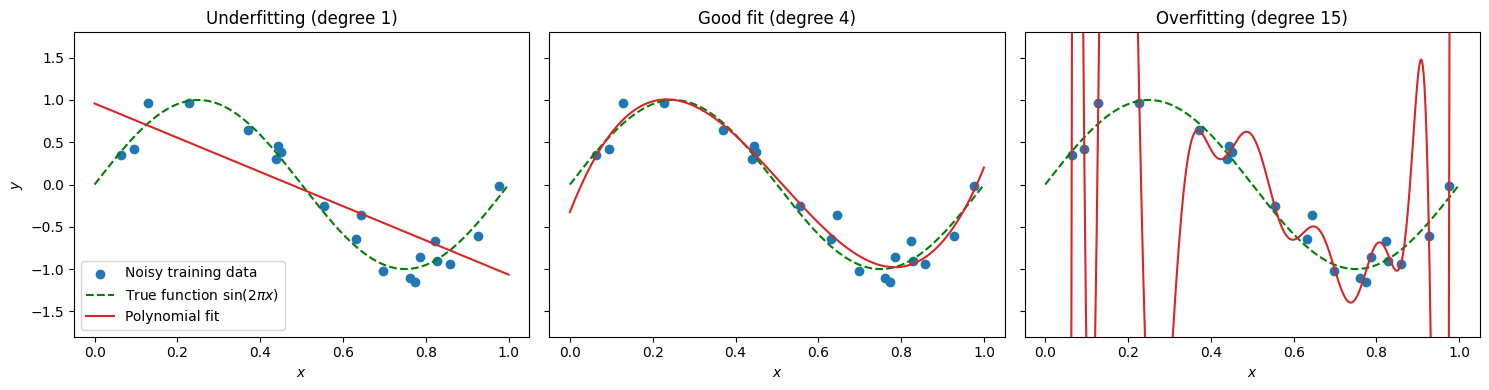

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Illustration only: the full experiment is in Section 6
rng = np.random.default_rng(42)
x = np.sort(rng.uniform(0, 1, 20))
y = np.sin(2 * np.pi * x) + rng.normal(0, 0.2, x.size)
x_plot = np.linspace(0, 1, 500)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
titles = ["Underfitting (degree 1)", "Good fit (degree 4)", "Overfitting (degree 15)"]

for ax, degree, title in zip(axes, [1, 4, 15], titles):
    model = np.polynomial.Polynomial.fit(x, y, degree)
    ax.scatter(x, y, color="tab:blue", label="Noisy training data")
    ax.plot(x_plot, np.sin(2 * np.pi * x_plot), "g--", label=r"True function $\sin(2\pi x)$")
    ax.plot(x_plot, model(x_plot), color="tab:red", label="Polynomial fit")
    ax.set_title(title)
    ax.set_xlabel("$x$")
    ax.set_ylim(-1.8, 1.8)

axes[0].set_ylabel("$y$")
axes[0].legend(loc="lower left")
plt.tight_layout()
plt.show()

**Figure 1: Underfitting, good fit and overfitting.** The degree 1 model is too simple: the straight line misses both the peak and the trough of the true function. The degree 4 model follows the true function closely. The degree 15 model passes very close to the training points, but between them it oscillates far away from the true function, so its predictions for new points would be poor.

### 1.2. Why is this important?

Every supervised learning model is trained on a finite sample and is later used on data outside that sample. Overfitting is therefore not a rare special case, but a risk that every model faces. Some examples of where it matters:

- **Medical diagnosis:** a model trained on patients from a single hospital may learn patterns that are specific to that dataset and perform worse on patients from other hospitals.
- **Price prediction:** a model for house prices may memorize the particular houses in its training set and give unreliable estimates for new properties.
- **Finance:** a trading strategy tuned too closely to historical data may look excellent on past data and fail on future data.

### 1.3. Objectives and scope

The objectives of this project are to:

1. Implement linear regression from scratch using the normal equation and justify the mean squared error loss through maximum likelihood (Section 4).
2. Use polynomial regression to demonstrate underfitting and overfitting by comparing training and test error for different polynomial degrees (Sections 5 and 6).
3. Derive the bias-variance decomposition of the expected error and confirm it with a simulation (Section 7).
4. Derive and implement Ridge (L2) regularization, explain Lasso (L1) regularization mathematically and geometrically, and study the effect of the regularization strength $\lambda$ (Section 8).
5. Implement k-fold cross-validation from scratch and use it to select the polynomial degree and $\lambda$ (Section 9).
6. Apply these methods to a real-world dataset, the diabetes dataset [3] (Section 10).

All methods implemented from scratch are verified against the corresponding implementations in scikit-learn [2].

**Out of scope:** the project focuses only on regression with a squared error loss. Classification, neural networks and deep learning, as well as other regularization techniques such as dropout, early stopping and data augmentation, are not covered.

### 1.4. Assumptions

- **Data-generating process:** the data is generated as $y = f(x) + \varepsilon$, where $f$ is an unknown function and $\varepsilon$ is random noise. With synthetic data, $f$ is known, so we can compare every model with the true answer.
- **Independent and identically distributed (i.i.d.) samples:** all training and test points come independently from the same distribution. Without this assumption, the test error would not be a fair estimate of the error on future data.
- **Gaussian noise with zero mean:** $\varepsilon \sim \mathcal{N}(0, \sigma^2)$. This assumption is what connects maximum likelihood to the mean squared error (Section 4.3), and $\sigma^2$ appears as the irreducible error in the bias-variance decomposition (Section 7).
- **Polynomial approximation:** the true function can be approximated well by a polynomial of moderate degree. This justifies the use of polynomial regression in Section 5.
- **Real-world data:** for the diabetes dataset, we assume that a linear model of the features is a reasonable approximation of the target.



## 2. Setup

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

## 3. Data

### 3.1. Synthetic data
We generate data from a known function and add noise, so we know the "true" answer:
$$ y = f(x) + \varepsilon, \quad \varepsilon \sim \mathcal{N}(0, \sigma^2) $$


We choose the true function $f(x) = \sin(2\pi x)$ on the interval $[0, 1]$, generate 30 points and add Gaussian noise with $\sigma = 0.2$.

**Why synthetic data?** We use synthetic data because we know the exact formula behind it. This is important because we can compare every model with the true function and evaluate it properly. With real data, the true function is unknown.

**Why $\sin(2\pi x)$?** The sine function has peaks and troughs, and that is why a straight line cannot describe it well. If the true function were a straight line, we could not show underfitting, because even the simplest model would describe it well. With the sine function, we can show both underfitting and overfitting. The sine is also not a polynomial, and this is important: the polynomial models we will use later can only be a close approximation of the true function, but never exactly equal to it. This is also the situation with real data, where every model is only an approximation.

**Why 30 points?** Overfitting depends on the ratio between the amount of data and the complexity of the model, so a small number of points is necessary to show overfitting. With many points, even a complex model cannot memorize all of them and is forced to follow the true function.

**Why $\sigma = 0.2$?** If $\sigma = 0$, there is no noise, so there is nothing for the model to memorize by mistake and overfitting cannot be shown. If $\sigma = 1$, the noise is as large as the sine itself and its shape is lost in the noise. With $\sigma = 0.2$, the shape of the sine is clearly visible, but there is enough noise for a complex model to overfit.


In [3]:
def true_function(x):
    """
    The true function f(x) = sin(2*pi*x) that generates the data.
    """
    return np.sin(2 * np.pi * x)

def generate_data(num_points, noise_std, x_min = 0, x_max = 1):
    """
    Generates num_points noisy samples of the true function in the range [x_min; x_max].
    Returns the arrays x and y
    """
    x = np.sort(np.random.uniform(x_min, x_max, num_points))
    noise = np.random.normal(0, noise_std, num_points)
    y = true_function(x) + noise
    return x, y

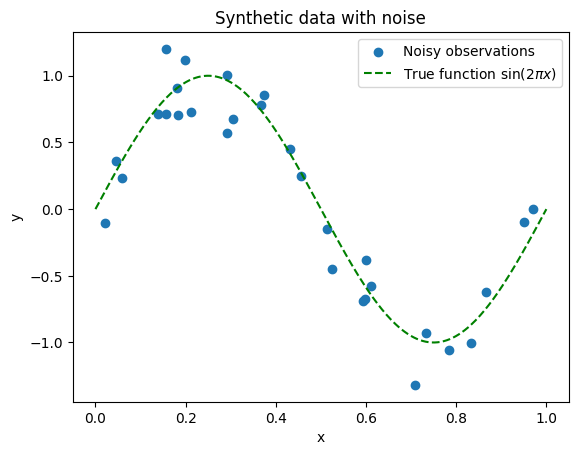

In [4]:
NUM_POINTS = 30
NOISE_STD = 0.2

x, y = generate_data(NUM_POINTS, NOISE_STD)
x_plot = np.linspace(0, 1, 300)
plt.scatter(x, y, color="tab:blue", label="Noisy observations")
plt.plot(x_plot, true_function(x_plot), "g--", label=r"True function $\sin(2\pi x)$")
plt.title("Synthetic data with noise")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

**Figure 2: Synthetic data with noise.** The noisy observations clearly follow the shape of the true function: they rise to a peak around $x = 0.25$ and fall to a trough around $x = 0.75$. Because of the noise, the points do not lie exactly on the curve, but all of them stay within about $0.4$ of it, so the underlying sine is easy to recognize.

### 3.2. Train / test split

If we test the model on the same data that it learned from, we cannot tell whether it has learned the true pattern or has just memorized the points. For this purpose, we evaluate it on new points that it has not seen. This is the test set. The points are chosen randomly, so that both the training and the test points are spread over the whole interval. Otherwise, the model would never see part of the curve.

In [5]:
def train_test_split(x, y, test_ratio = 0.3):
    """
    Randomly splits the data into a training set and a test set.
    Returns x_train, x_test, y_train, y_test
    """
    if len(x) != len(y):
        raise ValueError("x and y must have the same length")
    indices = np.random.permutation(len(x))
    test_size = int(len(x) * test_ratio)
    test_indices = indices[:test_size]
    train_indices = indices[test_size:]

    return x[train_indices], x[test_indices], y[train_indices], y[test_indices]
    

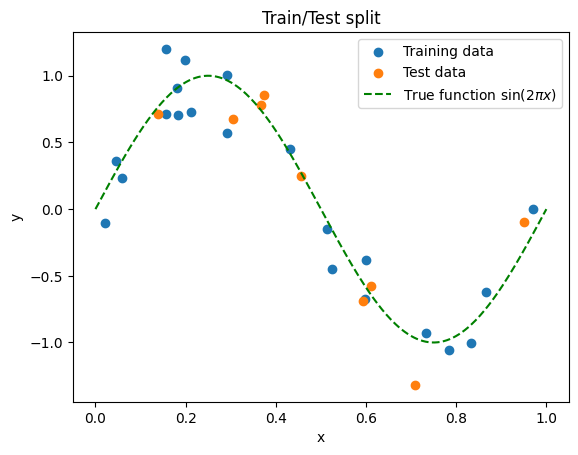

In [6]:
x_train, x_test, y_train, y_test = train_test_split(x, y)

plt.scatter(x_train, y_train, color="tab:blue", label="Training data")
plt.scatter(x_test, y_test, color="tab:orange", label="Test data")
plt.plot(x_plot, true_function(x_plot), "g--", label=r"True function $\sin(2\pi x)$")
plt.title("Train/Test split")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

**Figure 3: Train / test split.** The 30 points are randomly divided into 21 training points (blue) and 9 test points (orange). The test points are spread over the whole interval and include points near both the peak and the trough of the sine. This means that the test set checks the model on every part of the curve, not only on one region.

## 4. Linear Regression from Scratch

### 4.1. The model and the loss function
$$ \hat{\mathbf{y}} = X\mathbf{w}, \qquad L(\mathbf{w}) = \frac{1}{n}\lVert \mathbf{y} - X\mathbf{w} \rVert^2 $$

**The model.** $X$ is the design matrix with $n$ rows and 2 columns, where each row is one training point: the first column contains only ones and the second column contains the $x$ values (in our case $n = 21$). $\mathbf{w} = [w_0, w_1]$ is the weight vector, where $w_0$ is the intercept (the value of $\hat{y}$ when $x = 0$) and $w_1$ is the slope (how much $\hat{y}$ changes when $x$ increases by 1). The column of ones makes the intercept part of the matrix product, because each row gives $1 \cdot w_0 + x_i \cdot w_1$. Without it, the line would always pass through the origin $(0, 0)$. The result $\hat{\mathbf{y}}$ is a vector of $n$ predictions, one for each training point. The matrix form computes all of them in one operation, and the same code works for any number of columns, so we will reuse it for polynomial regression in Section 5.

**The loss.** $\mathbf{y} - X\mathbf{w}$ is the vector of residuals, the vertical distances $y_i - \hat{y}_i$ between each data point and the line. $\lVert \cdot \rVert^2$ squares every residual and sums them, and the factor $\frac{1}{n}$ turns this sum into an average, so the loss does not depend on the number of points and train and test errors can be compared. Squaring prevents positive and negative errors from cancelling out, penalizes large errors more than small ones and makes $L(\mathbf{w})$ a smooth function of $\mathbf{w}$, which we will differentiate in Section 4.2. This loss is exactly what our `mean_squared_error` function computes.

### 4.2. Deriving the normal equation

We want the weights $\mathbf{w}$ that make the loss $L(\mathbf{w})$ as small as possible. At the minimum of a smooth function the slope is zero in every direction, so all partial derivatives must be zero at the same time. Together they form the gradient $\nabla L(\mathbf{w})$, and the condition for the minimum is $\nabla L(\mathbf{w}) = \mathbf{0}$.

**Step 1: expand the loss.** Using $\lVert \mathbf{v} \rVert^2 = \mathbf{v}^T\mathbf{v}$ and the rule $(X\mathbf{w})^T = \mathbf{w}^TX^T$, we expand the loss in the same way as $(a - b)^2 = a^2 - 2ab + b^2$:

$$ L(\mathbf{w}) = \frac{1}{n}(\mathbf{y} - X\mathbf{w})^T(\mathbf{y} - X\mathbf{w}) = \frac{1}{n}\Big(\mathbf{y}^T\mathbf{y} - 2\,\mathbf{w}^TX^T\mathbf{y} + \mathbf{w}^TX^TX\mathbf{w}\Big) $$

The two middle terms $\mathbf{y}^TX\mathbf{w}$ and $\mathbf{w}^TX^T\mathbf{y}$ are the same number, which is why they combine into $2\,\mathbf{w}^TX^T\mathbf{y}$.

**Step 2: take the gradient.** The first term $\mathbf{y}^T\mathbf{y}$ does not depend on $\mathbf{w}$, so its derivative is zero. For the other two terms we use the vector versions of the rules $(cw)' = c$ and $(kw^2)' = 2kw$ [4, 5]:

$$ \nabla_{\mathbf{w}}\big(\mathbf{w}^TX^T\mathbf{y}\big) = X^T\mathbf{y}, \qquad \nabla_{\mathbf{w}}\big(\mathbf{w}^TX^TX\mathbf{w}\big) = 2X^TX\mathbf{w} $$

$$ \nabla L(\mathbf{w}) = \frac{1}{n}\Big(-2X^T\mathbf{y} + 2X^TX\mathbf{w}\Big) $$

**Step 3: set the gradient to zero.** Multiplying by $\frac{n}{2}$ and moving the term with $\mathbf{y}$ to the right side gives the **normal equation**:

$$ X^TX\mathbf{w} = X^T\mathbf{y} \qquad \Longrightarrow \qquad \mathbf{w} = (X^TX)^{-1}X^T\mathbf{y} $$

The second form is valid only when $X^TX$ is invertible. The loss is a quadratic "bowl" that opens upwards, so this point is a minimum and not a maximum. In `fit_linear_regression` we solve the normal equation with `np.linalg.solve` instead of computing the inverse matrix, because it is faster and numerically more stable. The derivation also does not depend on the number of columns of $X$, so the same function will work for polynomial regression in Section 5.

### 4.3. Probabilistic view (Maximum Likelihood)

The mean squared error is not an arbitrary choice: it follows from the assumption of Gaussian noise in Section 1.4 [4]. Our model says that $y_i = \mathbf{x}_i^T\mathbf{w} + \varepsilon_i$ with $\varepsilon_i \sim \mathcal{N}(0, \sigma^2)$, where $\mathbf{x}_i^T$ is the $i$-th row of $X$. This means that each observed $y_i$ is spread around the prediction $\hat{y}_i = \mathbf{x}_i^T\mathbf{w}$ like a bell curve with width $\sigma$:

$$ p(y_i \mid \mathbf{x}_i, \mathbf{w}) = \frac{1}{\sqrt{2\pi\sigma^2}}\exp\!\left(-\frac{(y_i - \hat{y}_i)^2}{2\sigma^2}\right) $$

Points close to the line have a high probability, and points far from it have a very low probability. Because the samples are i.i.d., the probability of observing the whole dataset, called the **likelihood**, is the product of the individual probabilities:

$$ p(\mathbf{y} \mid X, \mathbf{w}) = \prod_{i=1}^{n} p(y_i \mid \mathbf{x}_i, \mathbf{w}) $$

The logarithm turns the product into a sum and does not change the location of the maximum, because it is an increasing function:

$$ \log p(\mathbf{y} \mid X, \mathbf{w}) = -\frac{n}{2}\log(2\pi\sigma^2) - \frac{1}{2\sigma^2}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 $$

The first term and the factor $\frac{1}{2\sigma^2}$ do not depend on $\mathbf{w}$. Because of the minus sign, the log-likelihood is largest when the sum of squared residuals is smallest, and this sum is $n$ times the MSE. Therefore, **maximizing the likelihood is the same as minimizing the MSE**, and the maximum likelihood weights are exactly the solution of the normal equation from Section 4.2. If the noise were not Gaussian (for example, with many large outliers), this argument would lead to a different loss function.

In [7]:
def fit_linear_regression(X, y):
    """
    Finds the weights using the normal equation
    """
    xtx = X.T @ X
    xty = X.T @ y
    return np.linalg.solve(xtx, xty)


def predict(X, w):
    """
    Returns the predictions of the model
    """
    return X @ w


def mean_squared_error(y_true, y_pred):
    """
    Calculates the mean squared error
    """
    return np.mean((y_true - y_pred) ** 2)

In [8]:
# design matrices
X_train = np.column_stack([np.ones(len(x_train)), x_train])
X_test = np.column_stack([np.ones(len(x_test)), x_test])

# fit on the TRAINING data
w = fit_linear_regression(X_train, y_train)

# Make predictions
y_train_pred = predict(X_train, w)
y_test_pred = predict(X_test, w)

# Calculate errors
train_mse = mean_squared_error(y_train, y_train_pred)
test_mse = mean_squared_error(y_test, y_test_pred)

print("Weights: w0 =", w[0], ", w1 =", w[1])
print("Train MSE:", train_mse)
print("Test MSE:", test_mse)

Weights: w0 = 0.8744533525105839 , w1 = -1.818388225813362
Train MSE: 0.2246188774485666
Test MSE: 0.2992132241021882


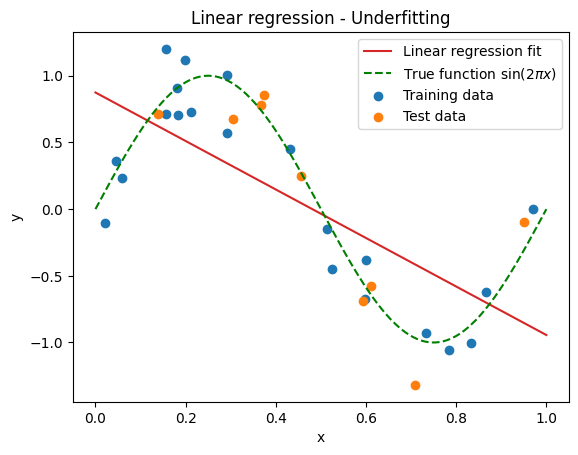

In [9]:
x_plot_design = np.column_stack([np.ones(len(x_plot)), x_plot])
y_plot_pred = predict(x_plot_design, w)
plt.plot(x_plot, y_plot_pred, color="tab:red", label="Linear regression fit")
plt.plot(x_plot, true_function(x_plot), "g--", label=r"True function $\sin(2\pi x)$")
plt.scatter(x_train, y_train, color="tab:blue", label="Training data")
plt.scatter(x_test, y_test, color="tab:orange", label="Test data")
plt.title("Linear regression - Underfitting")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

**Figure 4: Linear regression fit.** The figure shows the best straight line through the training data. The line goes down from left to right and misses both the peak and the trough of the sine, on the training points as well as on the test points. The MSE on both the training set (0.225) and the test set (0.299) is more than 5 times larger than the noise level $\sigma^2 = 0.04$, so the model has not learned the shape of the data. The two errors are close to each other, which means that the model has not memorized the training data either. This is a typical example of **underfitting**: a straight line is too simple to describe the sine.

### 4.4. Validation against scikit-learn

We compared the weights from our implementation of the normal equation with scikit-learn's `LinearRegression`, fitted on the same design matrix `X_train` (with `fit_intercept=False`, because `X_train` already contains the column of ones). The two sets of weights are identical up to rounding errors (`np.allclose` returns `True`). This confirms that our implementation of the normal equation is correct.

In [10]:
# Fit scikit-learn's model on the same design matrix X_train.
# fit_intercept=False because X_train already contains the column of ones.
sk_model = LinearRegression(fit_intercept=False)
sk_model.fit(X_train, y_train)

# Compare the weights
print("Our weights:     ", w)
print("sklearn weights: ", sk_model.coef_)

# np.allclose checks if two arrays are equal up to tiny rounding errors
print("Same weights?", np.allclose(w, sk_model.coef_))

Our weights:      [ 0.87445335 -1.81838823]
sklearn weights:  [ 0.87445335 -1.81838823]
Same weights? True


## 5. Polynomial Regression

A straight line cannot describe the sine, so we give the model more flexibility by adding powers of $x$:

$$ \hat{y} = w_0 + w_1x + w_2x^2 + \dots + w_dx^d $$

where $d$ is the degree of the polynomial. The curve is not a straight line in $x$, but the model is still **linear in the weights** [4]. The values of $x$ come from the data, so for a given point $x, x^2, \dots, x^d$ are just known numbers. For example, for $x = 0.5$ the model becomes $\hat{y} = w_0 + 0.5\,w_1 + 0.25\,w_2 + \dots$: every weight appears only to the first power and is multiplied by a known number. The derivation of the normal equation in Section 4.2 only uses the fact that $\hat{\mathbf{y}} = X\mathbf{w}$, so it is still valid.

### 5.1. The design (Vandermonde) matrix

The only thing that changes is the design matrix. Each row is one data point and each column is one power of $x$, from $x^0 = 1$ to $x^d$, so the matrix has $d + 1$ columns. This matrix is called the **Vandermonde matrix**:

$$ X = \begin{bmatrix} 1 & x_1 & x_1^2 & \dots & x_1^d \\ 1 & x_2 & x_2^2 & \dots & x_2^d \\ \vdots & \vdots & \vdots & \ddots & \vdots \\ 1 & x_n & x_n^2 & \dots & x_n^d \end{bmatrix} $$

The design matrix from Section 4 is the special case $d = 1$, with the columns $[1, x]$. Therefore `fit_linear_regression` and `predict` can be reused without any change; we only need a new function that builds $X$.

Higher powers of $x$ create a numerical problem. All our $x$ values are between 0 and 1, so the high powers become very small: for example, $0.5^{15} \approx 0.00003$. To have a visible effect on the prediction, the weight in front of such a column must be very large. In addition, the columns $x^{14}$ and $x^{15}$ are almost the same, so the model can give them very large weights with opposite signs that almost cancel at the training points but not between them. We will measure this effect in Section 6, and it is the main motivation for regularization in Section 8.

In [11]:
def polynomial_features(x, degree):
    """
    Returns the matrix [1, x, x^2, ..., x^degree]
    """
    return np.column_stack([x ** k for k in range(degree + 1)])


In [12]:
# sklearn expects x as a column (2D array)
x_train_column = x_train.reshape(-1, 1)
sk_poly = PolynomialFeatures(degree=3).fit_transform(x_train_column)

print("Same matrix as sklearn?", np.allclose(polynomial_features(x_train, 3), sk_poly))

Same matrix as sklearn? True


### 5.2. Fitting polynomials of different degrees

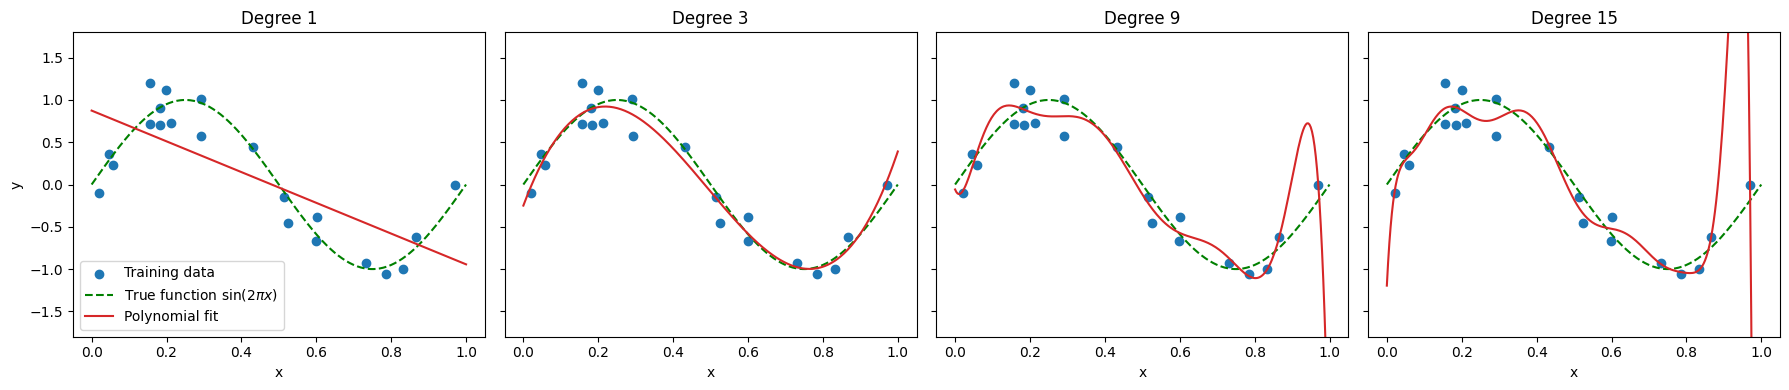

In [13]:
degrees = [1, 3, 9, 15]
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)

for ax, degree in zip(axes, degrees):
    # 1. Build the design matrices
    X_train_poly = polynomial_features(x_train, degree)
    X_plot_poly = polynomial_features(x_plot, degree)

    # 2. Fit on the training data and predict on the smooth x_plot
    w_poly = fit_linear_regression(X_train_poly, y_train)
    y_plot_poly = predict(X_plot_poly, w_poly)

    # 3. Plot
    ax.scatter(x_train, y_train, color="tab:blue", label="Training data")
    ax.plot(x_plot, true_function(x_plot), "g--", label=r"True function $\sin(2\pi x)$")
    ax.plot(x_plot, y_plot_poly, color="tab:red", label="Polynomial fit")
    ax.set_title(f"Degree {degree}")
    ax.set_xlabel("x")
    ax.set_ylim(-1.8, 1.8)

axes[0].set_ylabel("y")
axes[0].legend(loc="lower left")
plt.tight_layout()
plt.show()

**Figure 5: Polynomial fits of degree 1, 3, 9 and 15.** All four models are fitted with the same `fit_linear_regression` function; only the number of columns in the design matrix changes. 
- The degree 1 model is a straight line and underfits, as in Section 4. 
- The degree 3 model follows the true function $\sin(2\pi x)$ closely over the whole interval. 
- The degree 9 model starts to bend between the training points in order to pass closer to them, which means that it begins to fit the noise, and it drops sharply near $x = 1$. 
- The degree 15 model passes very close to almost every training point, but it oscillates strongly near the edges of the interval and leaves the plotted range (the $y$-axis is limited to $[-1.8, 1.8]$ for readability). The largest deviations appear where there is no training data, for example between $x \approx 0.87$ and $x \approx 0.97$, and this is exactly where new points can appear. This is overfitting: the model fits the training data very well but does not describe the true function. 

In Section 6 we measure this effect with the training and test errors.

## 6. Overfitting and Underfitting
> TODO: Plot the train error and the test error as a function of the polynomial degree. Explain the U-shaped test error curve.

> TODO: Look at the size of the weights for high degrees. What happens to them? (This motivates regularization.)

## 7. The Bias-Variance Tradeoff

### 7.1. Derivation
> TODO: Derive the decomposition of the expected error:
$$ \mathbb{E}\left[(y - \hat{f}(x))^2\right] = \text{Bias}^2 + \text{Variance} + \sigma^2 $$

### 7.2. Simulation
> TODO: Generate many different datasets, fit a model on each one and estimate the bias and the variance for every degree.

## 8. Regularization: Ridge and Lasso

### 8.1. Ridge regression (L2)
$$ L(\mathbf{w}) = \lVert \mathbf{y} - X\mathbf{w} \rVert^2 + \lambda \lVert \mathbf{w} \rVert_2^2 $$
> TODO: Derive $\mathbf{w} = (X^TX + \lambda I)^{-1}X^T\mathbf{y}$. Why is this matrix always invertible for $\lambda > 0$?

In [14]:
def fit_ridge_regression(X, y, regularization_strength):
    """
    Finds the weights of Ridge regression using its closed-form solution
    """
    # Write your code here
    pass

### 8.2. Lasso regression (L1)
$$ L(\mathbf{w}) = \lVert \mathbf{y} - X\mathbf{w} \rVert^2 + \lambda \lVert \mathbf{w} \rVert_1 $$
> TODO: Why is there no closed-form solution? Why does Lasso set some weights to exactly $0$?

### 8.3. Geometric interpretation
> TODO: Plot the L1 "diamond" and the L2 "circle" together with the contours of the loss.

### 8.4. The effect of $\lambda$
> TODO: Plot how the fitted curve and the weights change as $\lambda$ grows (coefficient paths).

## 9. Model Selection with Cross-Validation
> TODO: Explain k-fold cross-validation. Why is it better than a single train/test split?

In [15]:
def k_fold_cross_validation(X, y, fit_function, k = 5):
    """
    Splits the data into k folds, trains on k - 1 of them and tests on the remaining one.
    Returns the average test error
    """
    # Write your code here
    pass

> TODO: Use cross-validation to choose the best polynomial degree and the best $\lambda$.

## 10. Real-World Application
> TODO: Apply the methods to a real dataset (e.g. `sklearn.datasets.load_diabetes`). Compare plain linear regression, Ridge and Lasso. Which features does Lasso keep?

## 11. Discussion and Limitations
> TODO: What worked? What did not? What are the limitations of the assumptions from 1.4?

## 12. Conclusion and Next Steps
> TODO: Answer the question from the problem formulation. What could be explored next (e.g. regularization in neural networks, dropout, early stopping)?

## 13. References

1. Multimatics, "Detect and Prevent Overfitting and Underfitting in Machine Learning," *Multimatics Insight*, Sep. 29, 2023. [Online]. Available: https://multimatics.co.id/insight/sep/detect-and-prevent-overfitting-and-underfitting-in-machine-learning (accessed Oct. 23, 2026).

2. F. Pedregosa et al., "Scikit-learn: Machine Learning in Python," *Journal of Machine Learning Research*, vol. 12, pp. 2825–2830, 2011.

3. B. Efron, T. Hastie, I. Johnstone and R. Tibshirani, "Least Angle Regression," *Annals of Statistics*, vol. 32, no. 2, pp. 407–499, 2004.

4. M. P. Deisenroth, A. A. Faisal and C. S. Ong, *Mathematics for Machine Learning*. Cambridge University Press, 2020, ch. 9. [Online]. Available: https://mml-book.github.io/

5. K. B. Petersen and M. S. Pedersen, *The Matrix Cookbook*. Technical University of Denmark, 2012.